In [16]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, OUT, CHARTS = ROOT / "data/raw", ROOT / "data/processed", ROOT / "reports/charts"
sys.path.insert(0, str(ROOT / "src"))
import credit_analytics as ca
print("Ready:", ROOT)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Ready: c:\Users\lamid\Documents\banking-credit-analytics


In [17]:
cc = pd.read_csv(RAW / "credit_card_balance.csv",
                 usecols=["SK_ID_PREV", "MONTHS_BALANCE", "SK_DPD", "AMT_BALANCE"])
print(f"Rows: {len(cc):,} | Accounts: {cc['SK_ID_PREV'].nunique():,}")
print(f"Months covered: {cc['MONTHS_BALANCE'].min()} to {cc['MONTHS_BALANCE'].max()}")
cc.describe().round(1)

Rows: 3,840,312 | Accounts: 104,307
Months covered: -96 to -1


,SK_ID_PREV,MONTHS_BALANCE,AMT_BALANCE,SK_DPD
count,3840312.0,3840312.0,3840312.0,3840312.0
mean,1904503.6,-34.5,58300.2,9.3
std,536469.5,26.7,106307.0,97.5
min,1000018.0,-96.0,-420250.2,0.0
25%,1434385.0,-55.0,0.0,0.0
50%,1897122.0,-28.0,0.0,0.0
75%,2369327.8,-11.0,89046.7,0.0
max,2843496.0,-1.0,1505902.2,3260.0


In [18]:
panel = ca.prepare_card_panel(cc)
print(f"Panel: {len(panel):,} rows | {panel['loan_id'].nunique():,} accounts kept "
      f"(of {cc['SK_ID_PREV'].nunique():,})")
panel.head()

Panel: 2,720,781 rows | 92,585 accounts kept (of 104,307)


,loan_id,origination_date,snapshot_date,days_past_due,balance
0,2562384,2015-01-01,2018-07-01,0,56.970
1,1740877,2015-12-01,2018-06-01,0,31815.225
2,1389973,2017-10-01,2018-09-01,0,236572.110
3,2646502,2017-12-01,2018-06-01,7,82903.815
4,1079071,2017-11-01,2018-07-01,0,353451.645


In [19]:
vc = ca.vintage_curves(panel)
print(f"{vc.shape[1]} vintages")
vc.iloc[[3, 6, 12, 24], -8:].round(3)

27 vintages


vintage,2017Q1,2017Q2,2017Q3,2017Q4,2018Q1,2018Q2,2018Q3,2018Q4
mob,,,,,,,,
3,0.000,0.000,0.000,0.000,0.000,0.000,0.0,NaN
6,0.000,0.000,0.001,0.001,0.002,0.001,NaN,NaN
12,0.001,0.002,0.002,0.002,NaN,NaN,NaN,NaN
24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
import importlib
ca = importlib.reload(ca)
print(ca.BUCKET_LABELS)

['Current', '1-30', '31-60', '61-90', '90+']


In [21]:
vc30 = ca.vintage_curves(panel, bad_dpd=30)
old = [v for v in vc.columns if v < "2017"][-6:]   # older vintages have the full 24 months
print("Ever 90+ DPD:"); print(vc.loc[[6, 12, 24], old].round(3))
print("\nEver 30+ DPD:"); print(vc30.loc[[6, 12, 24], old].round(3))

Ever 90+ DPD:
vintage  2015Q3  2015Q4  2016Q1  2016Q2  2016Q3  2016Q4
mob                                                    
6         0.000   0.001   0.000   0.000   0.000   0.000
12        0.002   0.004   0.002   0.002   0.001   0.001
24        0.003   0.005   0.003   0.003   0.003   0.001

Ever 30+ DPD:
vintage  2015Q3  2015Q4  2016Q1  2016Q2  2016Q3  2016Q4
mob                                                    
6         0.004   0.006   0.004   0.003   0.001   0.000
12        0.006   0.008   0.005   0.005   0.002   0.002
24        0.008   0.010   0.006   0.006   0.005   0.003


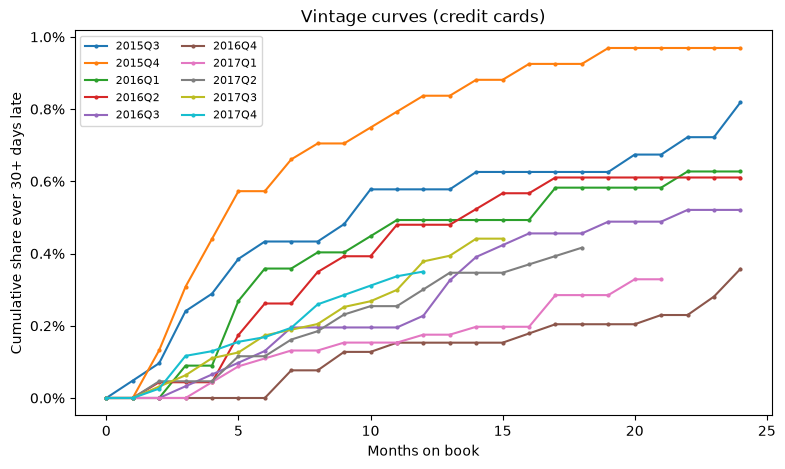

In [26]:
show = [v for v in vc30.columns if "2015Q3" <= v <= "2017Q4"]
fig, ax = plt.subplots(figsize=(9, 5))
for v in show:
    ax.plot(vc30.index, vc30[v], marker="o", ms=2, label=v)
ax.set(xlabel="Months on book", ylabel="Cumulative share ever 30+ days late",
       title="Vintage curves (credit cards)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.legend(ncol=2, fontsize=8)
plt.savefig(CHARTS / "02_vintage_curves.png", dpi=150)
plt.show()

In [24]:
ca = importlib.reload(ca)
vc = ca.vintage_curves(panel)
vc30 = ca.vintage_curves(panel, bad_dpd=30)
print("Any line going down?", bool((vc30.diff() < -1e-12).any().any()))

Any line going down? False


In [27]:
ca = importlib.reload(ca)
rr_bal = ca.roll_rates(panel, by="balance")
rr_cnt = ca.roll_rates(panel, by="count")
rr_bal.round(3)

next_bucket,Current,1-30,31-60,61-90,90+
bucket,,,,,
Current,0.975,0.025,0.000,0.000,0.000
1-30,0.621,0.369,0.010,0.000,0.000
31-60,0.397,0.337,0.138,0.128,0.001
61-90,0.330,0.150,0.151,0.133,0.235
90+,0.056,0.015,0.001,0.002,0.927


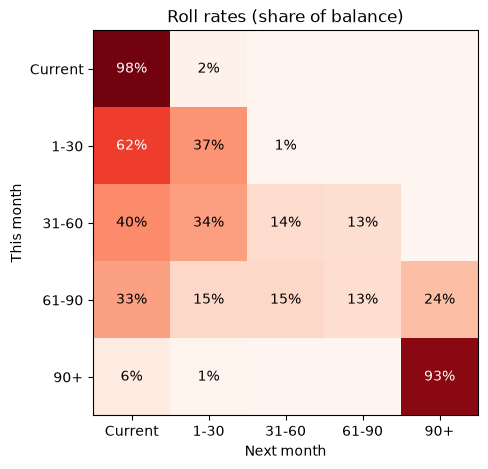

In [28]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(rr_bal.values, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(5), rr_bal.columns); ax.set_yticks(range(5), rr_bal.index)
ax.set(xlabel="Next month", ylabel="This month", title="Roll rates (share of balance)")
for i in range(5):
    for j in range(5):
        v = rr_bal.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.5 else "black")
plt.savefig(CHARTS / "02_roll_rates.png", dpi=150)
plt.show()

In [29]:
ca = importlib.reload(ca)
al = ca.annualised_loss(panel)
print(f"Annualised loss rate: {al:.2%}")

Annualised loss rate: 0.04%


In [30]:
import json
vc30.to_csv(OUT / "vintage_curves.csv")
rr_bal.to_csv(OUT / "roll_rates_balance.csv")
rr_cnt.to_csv(OUT / "roll_rates_count.csv")
json.dump({"accounts": int(panel["loan_id"].nunique()), "annualised_loss": al,
           "vintage_bad_definition": "ever 30+ DPD"},
          open(OUT / "portfolio_summary.json", "w"), indent=2)
print("Saved.")

Saved.
